In [1]:
import os
import json
import shutil
import warnings
import random
import base64

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib import rcParams
from datetime import datetime, timedelta

from tqdm import tqdm
import yfinance as yf

import seaborn as sns
from sklearn.metrics import (
roc_auc_score, average_precision_score, f1_score, accuracy_score,
precision_score, recall_score, confusion_matrix, precision_recall_curve,
classification_report
)
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression

In [2]:
variables = []
with open("00 Variables.txt", "r") as f:
    lines = f.readlines()
    hashes = 1
    for line in lines:
        s = line.strip()
        if not s:
            continue
        if s.startswith("#"):
            hashes = len(s) - len(s.lstrip("#"))
            comment_indent = (hashes - 1) * 2
            print(" " * comment_indent + "\033[92m" + s + "\033[0m")
        elif "=" in s:
            var = s.split("=", 1)[0].strip()
            variables.append(var)
            try:
                exec(s)
                black_indent = {1: 2, 2: 5, 3: 9, 4: 14}.get(hashes, (hashes - 1) * 2 + sum(range(hashes + 1)))
                print(" " * black_indent + f"{var} = {repr(eval(var))}")
            except Exception as e:
                black_indent = {1: 2, 2: 5, 3: 9, 4: 14}.get(hashes, (hashes - 1) * 2 + sum(range(hashes + 1)))
                print(" " * black_indent + s)
        else:
            black_indent = {1: 2, 2: 5, 3: 9, 4: 14}.get(hashes, (hashes - 1) * 2 + sum(range(hashes + 1)))
            print(" " * black_indent + s)

# Global Settings
  TICKER = '^GSPC'
  START_DATE_GLOBAL = '1998-01-01'
  START_DATE = '2024-12-20'
  END_DATE = '2025-06-30'
  WINDOW_SIZE = 120
  HORIZON_DAYS = 1
  CRASH_PERCENTILE = 0.05
  MAX_WINDOWS = 10000
  DATE_INFO = True
  INDICATOR_SIZE = 'small'
  CHART_NUM = 4
  TRANSPARENT = False
  NEWS_QUERY = 'Standard and Poors 500 stock index'
  api_key = 'your-api-key'
  MODEL_NAME = 'gpt-4.1'
  EMBEDDING_MODEL = 'text-embedding-3-small'
  RUN_TIMESTAMP = '20250726 1012'
  N_PREV = 6
  USE_IMAGES = True
# Path
  ## Layer 1
     L1_RESULTS = 'Results'
     L1_COMB_RESULTS = 'Combination Results'
  ## Layer 2
     L2_DATA = 'Data'
     L2_FIGURES = 'Figures'
     L2_OUTPUT = 'Output'
  ## Layer 3
     L3_FIGURES_CHARTS = 'Generate Charts'
# Output Name
  OHLCV = 'df_OHLCV'
  LOG_RETURNS = 'df_Log_Returns'
  INDICATORS = 'df_Indicators'
  CRASH_LABEL = 'df_Crash_Label'
  QUANTILE = 'df_Quantile_Series'
  VALID_DATES = 'df_Valid_Dates'
  NEWS_CACHE = 'df_News_Cache'
  FULL = 'df_Full'


## Input

In [16]:
RESULTS_DIR = f"{L1_RESULTS}/{L2_OUTPUT}/{RUN_TIMESTAMP}"
FIG_DIR = f"{L1_RESULTS}/{L2_FIGURES}/{L3_FIGURES_CHARTS}"

In [17]:
print(f"Inputing price data for {TICKER} from {START_DATE} to {END_DATE} ...")
df = pd.read_csv(f"{L1_RESULTS}/{L2_DATA}/{OHLCV}.csv", index_col=0, parse_dates=True)
print("Data inputted. Shape:", df.shape, "\n")

print("Inputing indicators...")
df_ind = pd.read_csv(f"{L1_RESULTS}/{L2_DATA}/{INDICATORS}.csv", index_col=0, parse_dates=True)
print("Indicators inputed. Shape:", df_ind.shape, "\n")

print("Inputing news data...")
df_news = pd.read_csv(f"{L1_RESULTS}/{L2_DATA}/{NEWS_CACHE}.csv", index_col=0, parse_dates=True)
print("News data inputed. Shape:", df_news.shape, "\n")

print("Inputing crash labels data...")
df_crash = pd.read_csv(f"{L1_RESULTS}/{L2_DATA}/{CRASH_LABEL}.csv", index_col=0, parse_dates=True)
print("Crash labels data inputed. Shape:", df_crash.shape, "\n")

print("Inputing LLM embeddings data...")
llm_embeddings = np.load(f"{RESULTS_DIR}/{LLM_EMBEDDINGS}.npy", allow_pickle=True)
llm_anomaly = pd.read_csv(f"{RESULTS_DIR}/{LLM_ANOMALY}.csv")

llm_embeddings_fewshot = np.load(f"{RESULTS_DIR}/{LLM_EMBEDDINGS_FEWSHOT}.npy", allow_pickle=True)
llm_anomaly_fewshot = pd.read_csv(f"{RESULTS_DIR}/{LLM_ANOMALY_FEWSHOT}.csv")

print("LLM embeddings shape:", llm_embeddings.shape)
print("LLM anomaly shape:", llm_anomaly.shape)

print("LLM embeddings few-shot shape:", llm_embeddings_fewshot.shape)
print("LLM anomaly few-shot shape:", llm_anomaly_fewshot.shape)

print("\nLLM Anomaly DataFrame:")
display(llm_anomaly)

print("\nLLM Anomaly Few-Shot DataFrame:")
display(llm_anomaly_fewshot)

Inputing price data for ^GSPC from 2023-07-01 to 2025-06-30 ...
Data inputted. Shape: (6913, 6) 

Inputing indicators...
Indicators inputed. Shape: (6674, 69) 

Inputing news data...
News data inputed. Shape: (10043, 1) 

Inputing crash labels data...
Crash labels data inputed. Shape: (6674, 3) 

Inputing LLM embeddings data...
LLM embeddings shape: (378, 1536)
LLM anomaly shape: (378, 15)
LLM embeddings few-shot shape: (378, 1536)
LLM anomaly few-shot shape: (378, 15)

LLM Anomaly DataFrame:


,date,image_path,technical_summary,context,news,future_dates,anomaly_label,anomaly_type,anomaly_score,key_signals,reasoning,success,crash_actual,future_min_logret,crash_threshold
0,2023-12-20,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 4698.35009765625, high: 4778.009765625,...",Summary statistics:\n close ...,Top 25 Stocks in the S&P 500 - Investopedia Eq...,2023-12-21 00:00:00,1,pattern break / regime shift,0.78,"['Sharp negative return after strong uptrend',...",The current window shows a sharp reversal afte...,True,0.0,0.010249,-0.013493
1,2023-12-21,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 4746.75, high: 4748.7099609375, low: 47...",Summary statistics:\n close ...,Industry Analysts Project 9% Increase in S&P 5...,2023-12-22 00:00:00,1,pattern break / regime shift (momentum exhaust...,0.75,"['RSI remains elevated (69.8, previously >80, ...",The current window shows a regime shift from a...,True,0.0,0.001659,-0.013564
2,2023-12-22,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 4754.6298828125, high: 4772.93994140625...",Summary statistics:\n close ...,Industry Analysts Project 9% Increase in S&P 5...,2023-12-26 00:00:00,1,Momentum/Overbought Regime Shift,0.82,"['RSI remains extremely high (75.2, previously...","The current environment shows a persistent, st...",True,0.0,0.004223,-0.013564
3,2023-12-26,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 4774.75, high: 4784.72021484375, low: 4...",Summary statistics:\n close ...,Industry Analysts Project 9% Increase in S&P 5...,2023-12-27 00:00:00,1,pattern break / overbought regime,0.82,"['RSI at 77.0 (overbought, highest in recent w...",The current session shows a strong upward move...,True,0.0,0.001429,-0.013564
4,2023-12-27,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 4781.580078125, high: 4785.39013671875,...",Summary statistics:\n close ...,Market Weight vs. Equal Weight S&P 500 ETFs: W...,2023-12-28 00:00:00,1,overbought_extreme_momentum_outlier,0.82,"['RSI > 80 (81.1, persistent over 70)', 'Stoch...",The current session shows a cluster of extreme...,True,0.0,0.000370,-0.013564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373,2025-06-18,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 5980.8701171875, high: 6018.25, low: 59...",Summary statistics:\n close ...,"Stock market today: Nasdaq, S&P 500 jump as Nv...",2025-06-20 00:00:00,1,Regime Shift / Pattern Break,0.72,['MACD negative crossover and sharp drop in MA...,The current window shows a clear regime shift ...,True,0.0,-0.002181,-0.020071
374,2025-06-20,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 5967.83984375, high: 6018.2001953125, l...",Summary statistics:\n close ...,Markets stumble as Wall Street sells off Big T...,2025-06-23 00:00:00,1,Volume Spike & Regime Shift,0.82,"['Volume spike: 7.45B vs mean 5.00B, 2.3 std a...",The current window shows a significant spike i...,True,0.0,0.009561,-0.020071
375,2025-06-23,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 6025.169921875, high: 6028.77001953125,...",Summary statistics:\n close ...,Markets stumble as Wall Street sells off Big T...,2025-06-24 00:00:00,1,momentum/volatility regime shift,0.72,['Price breakout above recent range and upper ...,The current window shows a notable shift: afte...,True,0.0,0.011060,-0.020071
376,2025-06-24,['Results/Figures/Generate Charts/Chart 1/^GSP...,"close: 6092.18017578125, high: 6101.759765625,...",Summary statistics:\n close ...,Stocks just did something they haven’t done in...,2025-06-25 00:00:00,1,pattern break / regime shift,0.85,['Close at new 20-day high (maxclose_20 = clos...,The current window shows a clear pattern break...,True,0.0,-0.000003,-0.020071



LLM Anomaly Few-Shot DataFrame:


,anomaly_label,anomaly_score,anomaly_type,key_signals,reasoning,success,date,image_path,context,technical_summary,crash_actual_x,error,crash_actual_y,future_min_logret,crash_threshold
0,1.0,0.82,regime_change,['Close price has sharply broken above upper B...,The market has transitioned from a period of c...,True,2023-12-20,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 4698.35009765625, high: 4778.009765625,...",0,NaN,0.0,0.010249,-0.013493
1,0.0,0.18,normal,"{'price_trend': 'Strong uptrend, price near up...","The market is in a strong, steady uptrend with...",True,2023-12-21,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 4746.75, high: 4748.7099609375, low: 47...",0,NaN,0.0,0.001659,-0.013564
2,1.0,0.75,spike,"{'RSI': 75.2, 'Stoch %K': 89.9, 'Price vs BB U...",The current window shows strong overbought sig...,True,2023-12-22,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 4754.6298828125, high: 4772.93994140625...",0,NaN,0.0,0.004223,-0.013564
3,0.0,0.15,normal,"{'close': 4774.75, 'return': 0.0042, 'rsi': 77...","The price continues to trend strongly upward, ...",True,2023-12-26,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 4774.75, high: 4784.72021484375, low: 4...",0,NaN,0.0,0.001429,-0.013564
4,1.0,0.92,regime_change,"['Close price at all-time high, breaking upper...",The market is exhibiting a clear and persisten...,True,2023-12-27,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 4781.580078125, high: 4785.39013671875,...",0,NaN,0.0,0.000370,-0.013564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373,0.0,0.10,normal,{'price_vs_bands': 'Price is near the upper Bo...,The current window shows stable price action w...,True,2025-06-18,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 5980.8701171875, high: 6018.25, low: 59...",0,NaN,0.0,-0.002181,-0.020071
374,1.0,0.72,spike,"{'volume': 7451500000.0, 'return': -0.00218, '...",The most notable anomaly is the large spike in...,True,2025-06-20,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 5967.83984375, high: 6018.2001953125, l...",0,NaN,0.0,0.009561,-0.020071
375,0.0,0.15,normal,"{'return': 0.00956, 'volatility': 0.2456, 'hv_...",The current window shows a strong positive ret...,True,2025-06-23,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 6025.169921875, high: 6028.77001953125,...",0,NaN,0.0,0.011060,-0.020071
376,1.0,0.85,spike,"{'return': 0.01106, 'logreturn': 0.01106, 'zsc...",The current window shows a significant positiv...,True,2025-06-24,['Results/Figures/Generate Charts/Chart 1/^GSP...,Summary statistics:\n close ...,"close: 6092.18017578125, high: 6101.759765625,...",0,NaN,0.0,-0.000003,-0.020071


## Definition

**Future work: move all columns name into `00 Variables.txt`**

In [18]:
def evaluate_anomaly_crash_prediction(df=llm_anomaly,
    results_csv=f"{RESULTS_DIR}/{LLM_ANOMALY}.csv", 
    anomaly_score_col="anomaly_score",
    anomaly_label_col="anomaly_label",
    crash_actual_col="crash_actual", 
    plot=True,
    n_bins=10,
    threshold=0.5,   # For converting score to label
):
    
    df[crash_actual_col] = df[crash_actual_col].shift(-1)
    df = df.dropna(subset=[anomaly_score_col, crash_actual_col])
    X = df[anomaly_score_col].astype(float).values.reshape(-1, 1)
    y = df[crash_actual_col].astype(int).values

    # --- Class balance
    n_crash, n_no_crash = np.sum(y == 1), np.sum(y == 0)
    print(f"Total samples: {len(y)} | Crashes: {n_crash} | No crash: {n_no_crash}")

    # --- Binary prediction from anomaly_score ---
    y_pred = (X.ravel() >= threshold).astype(int)
    print("\nClassification report (anomaly_score >= {:.2f} => crash):\n".format(threshold))
    print(classification_report(y, y_pred, digits=3))
    print("Confusion matrix:\n", confusion_matrix(y, y_pred))

    # --- ROC, AP, and other metrics ---
    auc_raw = roc_auc_score(y, X) if len(np.unique(y)) == 2 else None
    avg_prec_raw = average_precision_score(y, X) if len(np.unique(y)) == 2 else None
    print(f"\nRaw anomaly_score: ROC AUC={auc_raw:.4f}, AP={avg_prec_raw:.4f}" if auc_raw is not None else "[Single class: ROC/AUC N/A]")

    # --- Calibration ---
    iso = IsotonicRegression(out_of_bounds='clip')
    prob_iso = iso.fit_transform(X.ravel(), y)

    logreg = LogisticRegression()
    logreg.fit(X, y)
    prob_logreg = logreg.predict_proba(X)[:,1]

    prob_linear = (X.ravel() - X.min()) / (X.max() - X.min())

    # --- Evaluate all ---
    def safe_auc(y, prob):
        return roc_auc_score(y, prob) if len(np.unique(y)) == 2 else None
    def safe_ap(y, prob):
        return average_precision_score(y, prob) if len(np.unique(y)) == 2 else None

    aucs = {
        "raw": safe_auc(y, X.ravel()),
        "iso": safe_auc(y, prob_iso),
        "logreg": safe_auc(y, prob_logreg),
        "linear": safe_auc(y, prob_linear)
    }
    aps = {
        "raw": safe_ap(y, X.ravel()),
        "iso": safe_ap(y, prob_iso),
        "logreg": safe_ap(y, prob_logreg),
        "linear": safe_ap(y, prob_linear)
    }
    for name in ["raw", "iso", "logreg", "linear"]:
        print(f"{name.capitalize()} | ROC AUC={aucs[name]:.4f}, AP={aps[name]:.4f}" if aucs[name] is not None else f"{name.capitalize()} | ROC/AUC N/A")

    # --- Calibration and PR Plots ---
    if plot:
        fig, ax = plt.subplots(1,2, figsize=(12,4))
        for probs, name in zip(
            [np.clip(X.ravel(), 0, 1), np.clip(prob_iso, 0, 1), np.clip(prob_logreg, 0, 1), np.clip(prob_linear, 0, 1)],
            ["Anomaly", "Isotonic", "LogReg", "Linear"]
        ):
            frac_true, frac_pred = calibration_curve(y, probs, n_bins=n_bins)
            ax[0].plot(frac_pred, frac_true, marker="o", label=name)
        ax[0].plot([0,1], [0,1], "--", color="gray")
        ax[0].set_title("Calibration Plot (Reliability)")
        ax[0].set_xlabel("Predicted probability")
        ax[0].set_ylabel("Empirical probability")
        ax[0].legend()
        # PR Curve
        for probs, name in zip(
            [np.clip(X.ravel(), 0, 1), np.clip(prob_iso, 0, 1), np.clip(prob_logreg, 0, 1), np.clip(prob_linear, 0, 1)],
            ["Anomaly", "Isotonic", "LogReg", "Linear"]
        ):
            prec, rec, _ = precision_recall_curve(y, probs)
            ap = average_precision_score(y, probs) if len(np.unique(y)) == 2 else None
            ax[1].plot(rec, prec, label=f"{name} (AP={ap:.2f})")
        ax[1].set_title("Precision-Recall Curve")
        ax[1].set_xlabel("Recall")
        ax[1].set_ylabel("Precision")
        ax[1].legend()
        plt.tight_layout()
        plt.show()

    # --- Save calibrated probabilities
    df["prob_anomaly"] = np.clip(X.ravel(), 0, 1)
    df["prob_iso"] = np.clip(prob_iso, 0, 1)
    df["prob_logreg"] = np.clip(prob_logreg, 0, 1)
    df["prob_linear"] = np.clip(prob_linear, 0, 1)
    outpath = results_csv.replace(".csv", "_calibrated.csv")
    df.to_csv(outpath, index=False)
    print("Saved with calibrated probabilities:", outpath)

    # --- Save metrics to CSV ---
    metrics_path = results_csv.replace(".csv", "_metrics.csv")
    metrics_df = pd.DataFrame([{
        "method": "evaluate",
        "roc_auc_raw": aucs["raw"],
        "roc_auc_iso": aucs["iso"],
        "roc_auc_logreg": aucs["logreg"],
        "roc_auc_linear": aucs["linear"],
        "ap_raw": aps["raw"],
        "ap_iso": aps["iso"],
        "ap_logreg": aps["logreg"],
        "ap_linear": aps["linear"]
    }])
    metrics_df.to_csv(metrics_path, index=False)
    print("Saved evaluation metrics:", metrics_path)


    return {
        "raw": X.ravel(),
        "iso": prob_iso,
        "logreg": prob_logreg,
        "linear": prob_linear,
        "iso_model": iso,
        "logreg_model": logreg,
        "metrics": {"aucs": aucs, "aps": aps},
        "df": df
    }

In [19]:
def anomaly_crash_dashboard(
    df=llm_anomaly,
    anomaly_score_col="anomaly_score",
    crash_actual_col="crash_actual",
    plot_thresholds=True,
    optimize_threshold=True,
    save_path=None
):
    # --- 1. Load data ---
    df = df.dropna(subset=[anomaly_score_col, crash_actual_col])
    scores = df[anomaly_score_col].astype(float).values
    labels = df[crash_actual_col].astype(int).values

    # --- 2. Find optimal threshold (F1) ---
    thresholds = np.linspace(0, 1, 201)
    f1s, accs, precs, recs = [], [], [], []
    for thr in thresholds:
        pred = (scores >= thr).astype(int)
        f1s.append(f1_score(labels, pred, zero_division=0))
        accs.append(accuracy_score(labels, pred))
        precs.append(precision_score(labels, pred, zero_division=0))
        recs.append(recall_score(labels, pred, zero_division=0))
    best_idx = np.argmax(f1s)
    best_thr = thresholds[best_idx] if optimize_threshold else 0.5
    pred_best = (scores >= best_thr).astype(int)

    # --- 3. Metrics and confusion matrix ---
    auc_roc = roc_auc_score(labels, scores) if len(np.unique(labels)) == 2 else None
    auc_pr = average_precision_score(labels, scores) if len(np.unique(labels)) == 2 else None
    cm = confusion_matrix(labels, pred_best)
    print(f"Optimal threshold: {best_thr:.3f} (F1={f1s[best_idx]:.3f})")
    print("Confusion matrix:\n", cm)
    print(f"AUC-ROC: {auc_roc:.3f} | AP: {auc_pr:.3f}")

    # --- 4. Dashboard Plots ---
    fig = plt.figure(figsize=(20, 10))

    # 1. F1, Accuracy, Precision, Recall vs threshold
    ax1 = plt.subplot(2, 3, 1)
    ax1.plot(thresholds, f1s, label='F1')
    ax1.plot(thresholds, accs, label='Accuracy')
    ax1.plot(thresholds, precs, label='Precision')
    ax1.plot(thresholds, recs, label='Recall')
    if plot_thresholds:
        ax1.axvline(best_thr, color='k', linestyle='--', label=f'Best F1 @ {best_thr:.2f}')
    ax1.set_title('Score Metrics vs Threshold')
    ax1.set_xlabel('Threshold')
    ax1.set_ylabel('Score')
    ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax1.grid(True, alpha=0.3)

    # 2. Confusion Matrix
    ax2 = plt.subplot(2, 3, 2)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No Crash', 'Crash'], yticklabels=['No Crash', 'Crash'], ax=ax2)
    ax2.set_title('Confusion Matrix')
    ax2.set_xlabel('Predicted')
    ax2.set_ylabel('Actual')

    # 3. ROC Curve
    ax3 = plt.subplot(2, 3, 3)
    if auc_roc is not None:
        from sklearn.metrics import roc_curve
        fpr, tpr, _ = roc_curve(labels, scores)
        ax3.plot(fpr, tpr, label=f'AUC={auc_roc:.3f}')
        ax3.plot([0,1], [0,1], 'r--')
        ax3.set_title('ROC Curve')
        ax3.set_xlabel('FPR')
        ax3.set_ylabel('TPR')
        ax3.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
        ax3.grid(True, alpha=0.3)
    else:
        ax3.text(0.5, 0.5, 'ROC N/A', ha='center', va='center', fontsize=12)
        ax3.set_title('ROC Curve')

    # 4. Precision-Recall Curve
    ax4 = plt.subplot(2, 3, 4)
    if auc_pr is not None:
        prec, rec, _ = precision_recall_curve(labels, scores)
        ax4.plot(rec, prec, label=f'AP={auc_pr:.3f}')
        ax4.set_title('Precision-Recall')
        ax4.set_xlabel('Recall')
        ax4.set_ylabel('Precision')
        ax4.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
        ax4.grid(True, alpha=0.3)
    else:
        ax4.text(0.5, 0.5, 'PR N/A', ha='center', va='center', fontsize=12)
        ax4.set_title('Precision-Recall Curve')

    # 5. Score Distribution by Actual
    ax5 = plt.subplot(2, 3, 5)
    ax5.hist(scores[labels==0], bins=20, alpha=0.7, label='No Crash', color='skyblue', density=True)
    ax5.hist(scores[labels==1], bins=20, alpha=0.7, label='Crash', color='salmon', density=True)
    ax5.axvline(best_thr, color='k', linestyle='--', label=f'Cutoff={best_thr:.2f}')
    ax5.set_xlabel('Anomaly Score')
    ax5.set_ylabel('Density')
    ax5.set_title('Anomaly Score Distribution')
    ax5.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax5.grid(True, alpha=0.3)

    # 6. Calibration Curve
    ax6 = plt.subplot(2, 3, 6)
    prob_true, prob_pred = calibration_curve(labels, scores, n_bins=8, strategy='uniform')
    ax6.plot(prob_pred, prob_true, marker='o', label='Model')
    ax6.plot([0, 1], [0, 1], 'k--', label='Perfect')
    ax6.set_xlabel('Mean Predicted')
    ax6.set_ylabel('Empirical Frequency')
    ax6.set_title('Calibration Curve')
    ax6.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, transparent=True, bbox_inches='tight')
        print(f"Dashboard saved to {save_path}")
    plt.show()

    # --- 5. Print classification report
    print("\nClassification Report (Best Threshold):\n")
    print(classification_report(labels, pred_best, digits=3))

    # --- Save dashboard metrics to CSV ---
    if save_path:
        metrics_path = save_path.replace(".png", "_metrics.csv")
        dashboard_metrics = pd.DataFrame([{
            "method": "dashboard",
            "best_threshold": best_thr,
            "f1_best": f1s[best_idx],
            "auc_roc": auc_roc,
            "auc_pr": auc_pr,
            "tn": cm[0,0], "fp": cm[0,1],
            "fn": cm[1,0], "tp": cm[1,1]
        }])
        dashboard_metrics.to_csv(metrics_path, index=False)
        print("Saved dashboard metrics:", metrics_path)


    return {
        "thresholds": thresholds,
        "f1s": f1s,
        "best_threshold": best_thr,
        "confusion_matrix": cm,
        "auc_roc": auc_roc,
        "auc_pr": auc_pr
    }

In [20]:
def plot_anomaly_and_crashes_bars(
    df=llm_anomaly,
    anomaly_score_col="anomaly_score",
    crash_actual_col="crash_actual",
    future_min_logret_col="future_min_logret",
    date_col="date",
    save_path=None
):
    sns.set_theme(style="whitegrid")
    df[date_col] = pd.to_datetime(df[date_col])
    df = df.sort_values(date_col)

    years = sorted(df[date_col].dt.year.unique())
    for y in years:
        start = pd.Timestamp(f"{y-1}-11-30")
        end = pd.Timestamp(f"{y+1}-01-31")
        df_sub = df[(df[date_col] >= start) & (df[date_col] <= end)]
        if df_sub.empty:
            continue

        # Prepare figure
        fig, ax1 = plt.subplots(figsize=(18, 6))

        # Bar plot for anomaly scores (vibrant blue)
        bar_colors = plt.cm.Blues(df_sub[anomaly_score_col].fillna(0).values)
        bars = ax1.bar(df_sub[date_col], df_sub[anomaly_score_col].fillna(0), color=bar_colors, label="Anomaly Score", width=3)

        ax1.set_ylabel("Anomaly Score", color='blue', fontsize=14)
        ax1.set_ylim(0, 1.05)
        ax1.tick_params(axis='y', labelcolor='blue', labelsize=12)
        ax1.set_xlabel("Date", fontsize=14)
        ax1.tick_params(axis='x', labelrotation=30, labelsize=12)
        ax1.xaxis.set_major_locator(mdates.MonthLocator())
        ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

        # Line plot for future minimum log return (vibrant orange)
        ax2 = ax1.twinx()
        ax2.plot(df_sub[date_col], df_sub[future_min_logret_col].fillna(0), color='#FF7F0E', linewidth=2.5, label="Future Min Log Return")
        ax2.set_ylabel("Future Min Log Return", color='#FF7F0E', fontsize=14)
        ax2.tick_params(axis='y', labelcolor='#FF7F0E', labelsize=12)

        # Mark actual crashes with red X on anomaly bars
        crash_dates = df_sub[df_sub[crash_actual_col] == 1][date_col]
        crash_scores = df_sub[df_sub[crash_actual_col] == 1][anomaly_score_col]
        for cd, cs in zip(crash_dates, crash_scores):
            ax1.scatter(cd, cs + 0.05, color='red', marker='X', s=140, label="Actual Crash")

        # Remove duplicate legend entries for crashes
        handles, labels = ax1.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))

        # Title and grids
        ax1.set_title("Anomaly Scores (bars), Future Min Log Returns (line), and Actual Crashes (red X)\nOver Time",
                      fontsize=18, fontweight='bold', pad=20)
        ax1.grid(True, linestyle="--", alpha=0.4)
        ax1.minorticks_on()
        ax2.minorticks_on()

        # Legend below chart, nicely formatted
        fig.legend(by_label.values(), by_label.keys(),
                   loc='lower center', bbox_to_anchor=(0.5, -0.05),
                   ncol=3, fontsize=14, fancybox=True, shadow=True)

        fig.tight_layout()
        fig.subplots_adjust(bottom=0.25)
        fig.patch.set_facecolor('white')

        if save_path:
            sp = save_path.replace(".png", f"_{y}.png")
            fig.savefig(sp, transparent=True, bbox_inches='tight')
            print(f"Saved vibrant bar plot to {sp}")

        plt.show()

## Main Execution (Zero Shot)

Total samples: 377 | Crashes: 26 | No crash: 351

Classification report (anomaly_score >= 0.50 => crash):

              precision    recall  f1-score   support

           0      0.957     0.063     0.118       351
           1      0.071     0.962     0.132        26

    accuracy                          0.125       377
   macro avg      0.514     0.512     0.125       377
weighted avg      0.895     0.125     0.119       377

Confusion matrix:
 [[ 22 329]
 [  1  25]]

Raw anomaly_score: ROC AUC=0.6101, AP=0.1084
Raw | ROC AUC=0.6101, AP=0.1084
Iso | ROC AUC=0.6268, AP=0.1088
Logreg | ROC AUC=0.6101, AP=0.1084
Linear | ROC AUC=0.6101, AP=0.1084


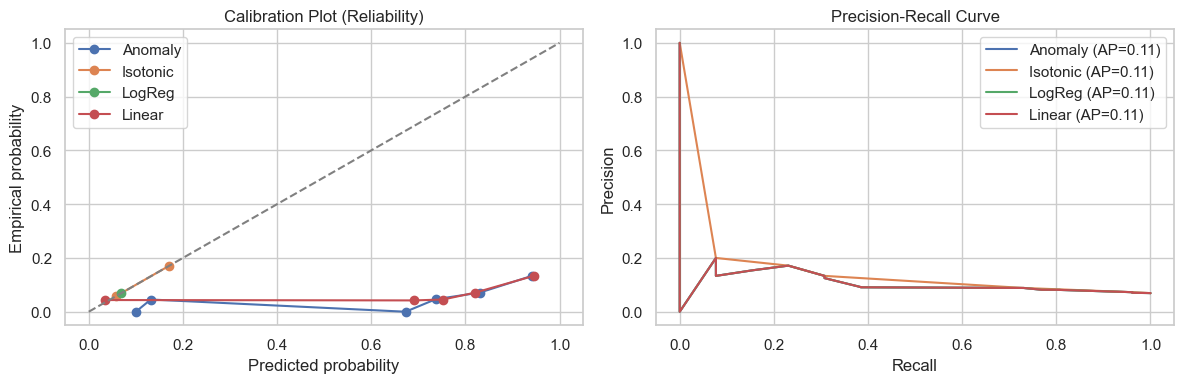

Saved with calibrated probabilities: Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_calibrated.csv
Saved evaluation metrics: Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_metrics.csv


/var/folders/0j/0cgjnq7x6_xgggqt92c7300r0000gn/T/ipykernel_16782/2924789302.py:92: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["prob_anomaly"] = np.clip(X.ravel(), 0, 1)
/var/folders/0j/0cgjnq7x6_xgggqt92c7300r0000gn/T/ipykernel_16782/2924789302.py:93: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["prob_iso"] = np.clip(prob_iso, 0, 1)
/var/folders/0j/0cgjnq7x6_xgggqt92c7300r0000gn/T/ipykernel_16782/2924789302.py:94: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Dat

In [21]:
calib = evaluate_anomaly_crash_prediction()

Optimal threshold: 0.925 (F1=0.197)
Confusion matrix:
 [[322  29]
 [ 20   6]]
AUC-ROC: 0.610 | AP: 0.108
Dashboard saved to Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_dashboard.png


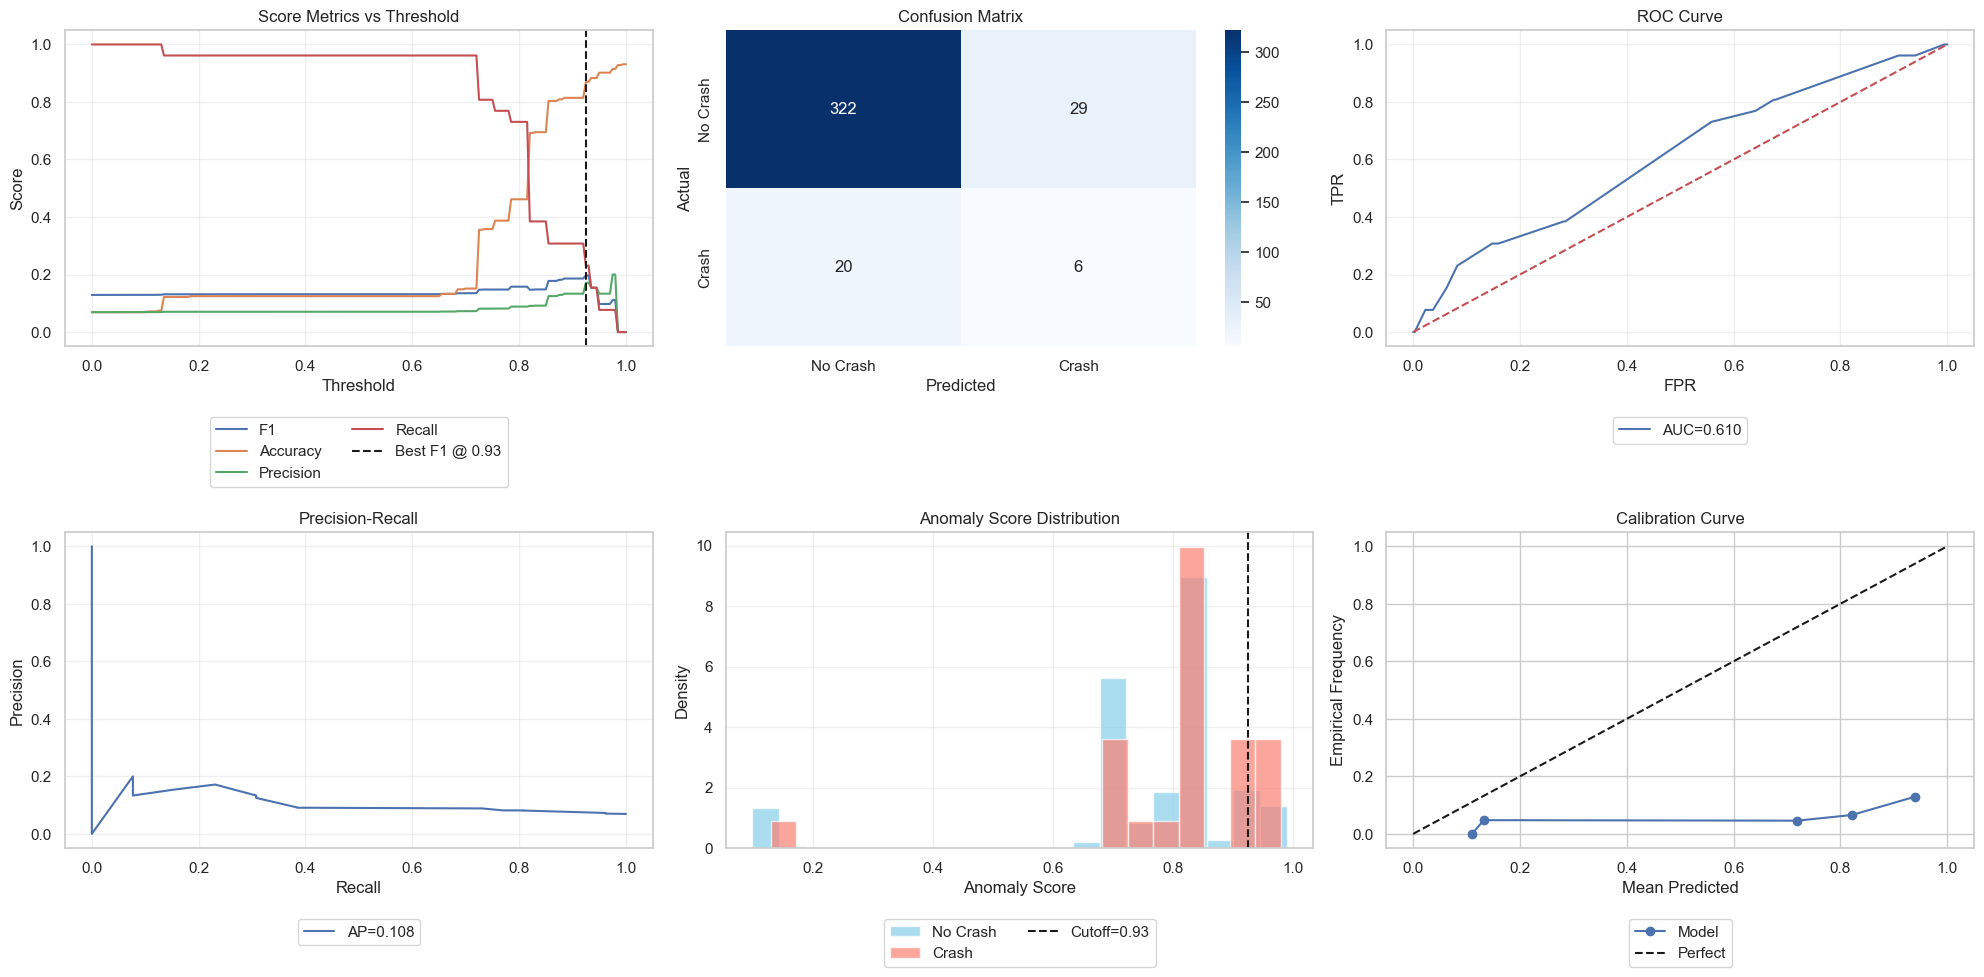


Classification Report (Best Threshold):

              precision    recall  f1-score   support

           0      0.942     0.917     0.929       351
           1      0.171     0.231     0.197        26

    accuracy                          0.870       377
   macro avg      0.556     0.574     0.563       377
weighted avg      0.888     0.870     0.879       377

Saved dashboard metrics: Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_dashboard_metrics.csv


In [22]:
results_dashboard_zero_shot = anomaly_crash_dashboard(
    anomaly_score_col="anomaly_score",
    crash_actual_col="crash_actual",
    plot_thresholds=True,
    optimize_threshold=True,
    save_path=f"{RESULTS_DIR}/{LLM_ANOMALY}_dashboard.png"
)

Saved vibrant bar plot to Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_bars_2023.png


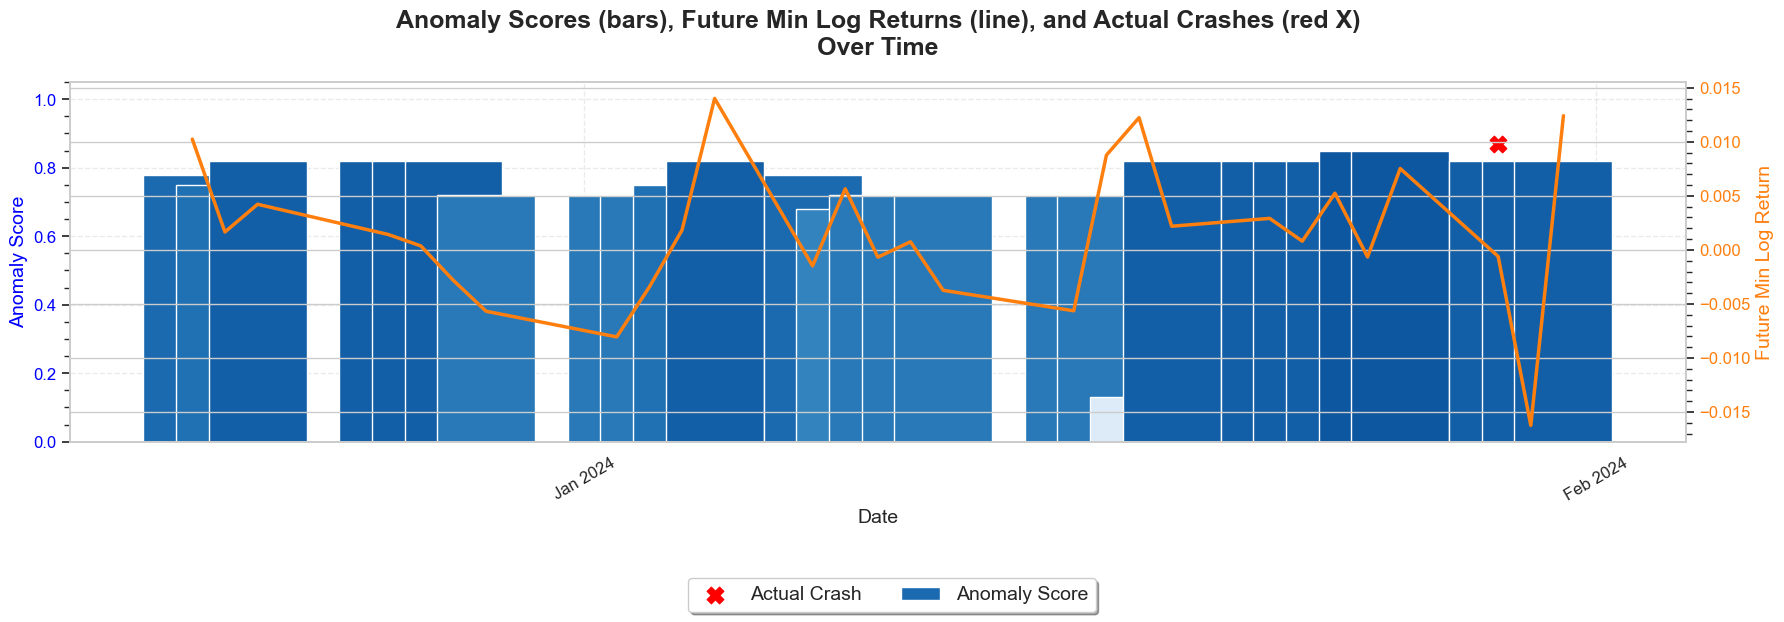

Saved vibrant bar plot to Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_bars_2024.png


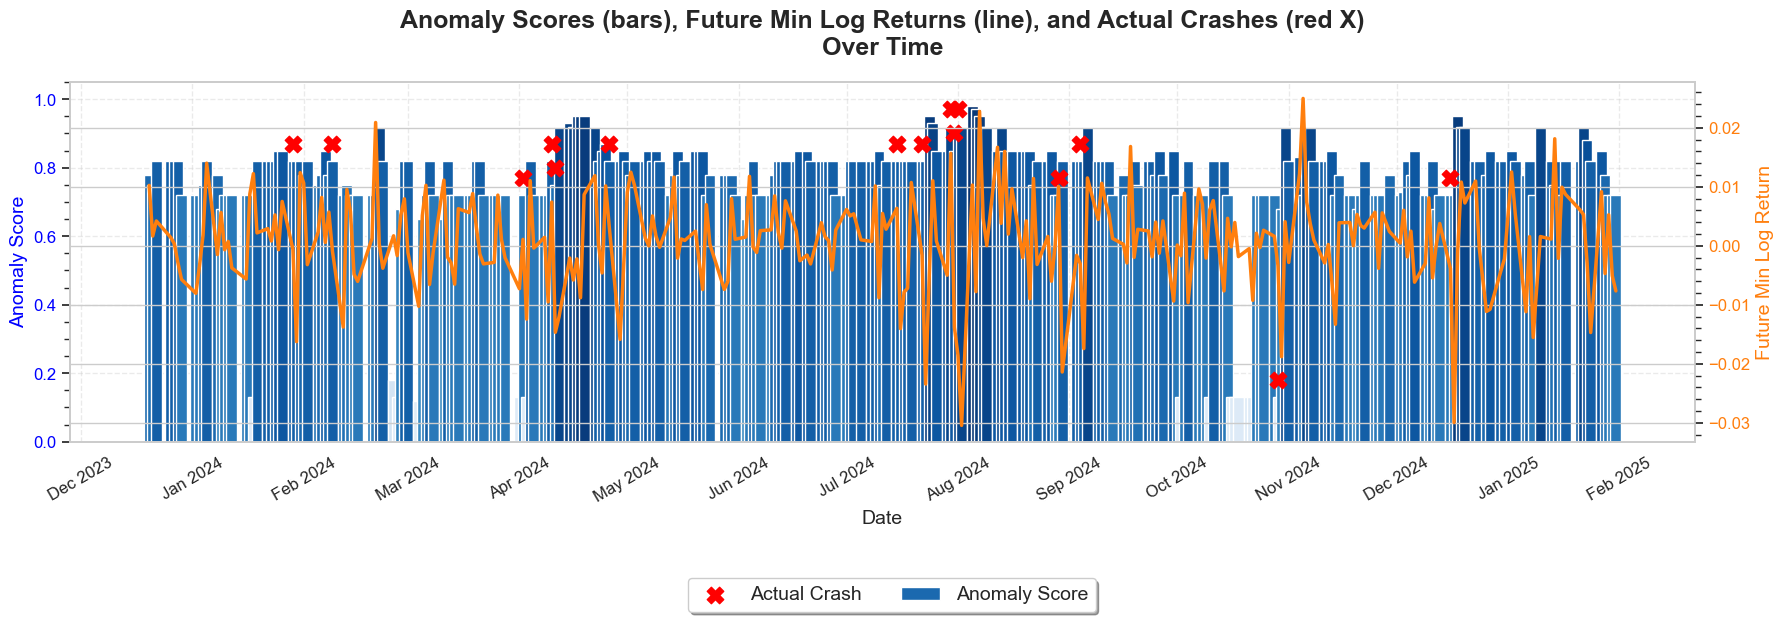

Saved vibrant bar plot to Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_bars_2025.png


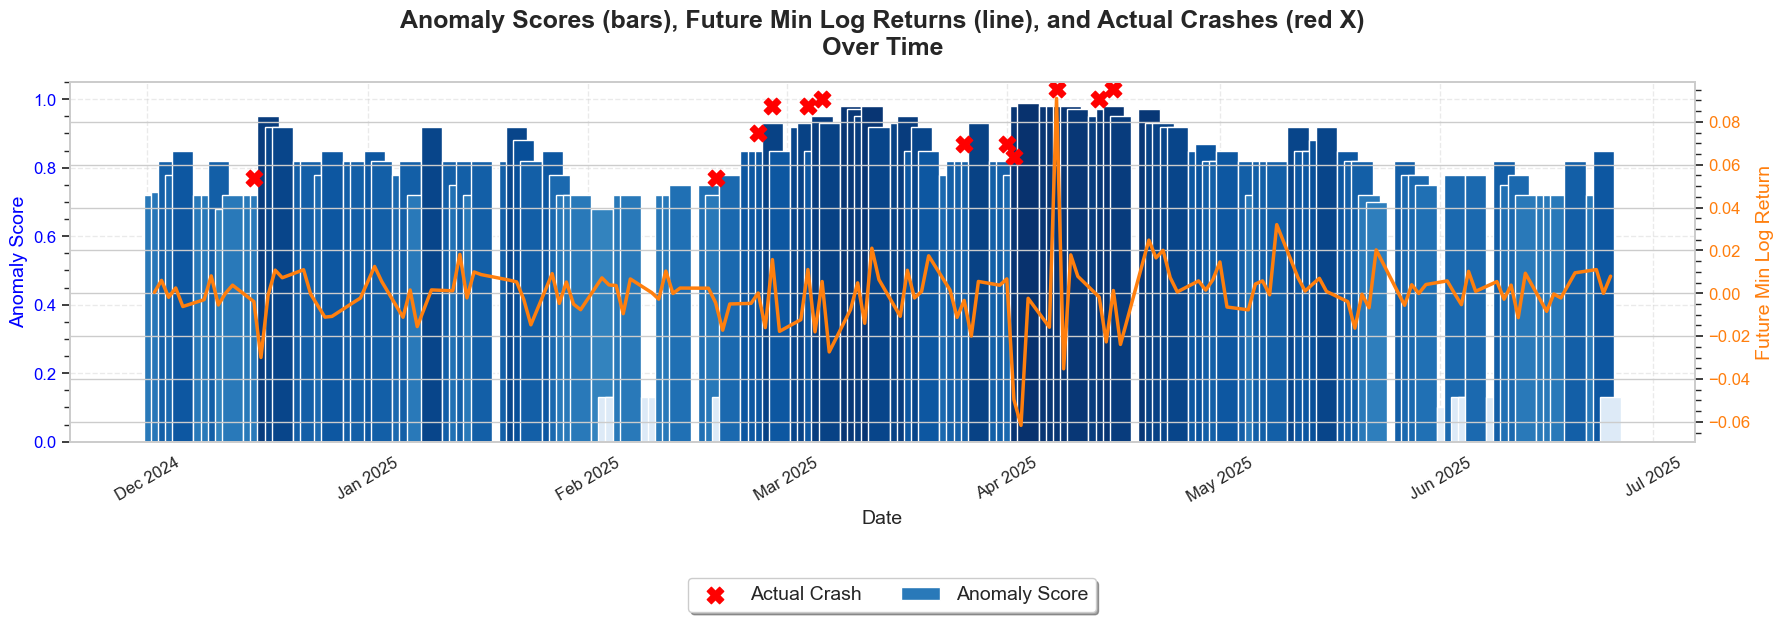

In [23]:
plot_anomaly_and_crashes_bars(
    df=llm_anomaly,
    anomaly_score_col="anomaly_score",
    crash_actual_col="crash_actual",
    future_min_logret_col="future_min_logret",
    date_col="date",
    save_path=f"{RESULTS_DIR}/{LLM_ANOMALY}_bars.png"
)

## Main Execution (Few Shot)

Total samples: 355 | Crashes: 24 | No crash: 331

Classification report (anomaly_score >= 0.50 => crash):

              precision    recall  f1-score   support

           0      0.954     0.314     0.473       331
           1      0.077     0.792     0.141        24

    accuracy                          0.346       355
   macro avg      0.516     0.553     0.307       355
weighted avg      0.895     0.346     0.450       355

Confusion matrix:
 [[104 227]
 [  5  19]]

Raw anomaly_score: ROC AUC=0.6106, AP=0.1160
Raw | ROC AUC=0.6106, AP=0.1160
Iso | ROC AUC=0.6382, AP=0.1152
Logreg | ROC AUC=0.6106, AP=0.1160
Linear | ROC AUC=0.6106, AP=0.1160


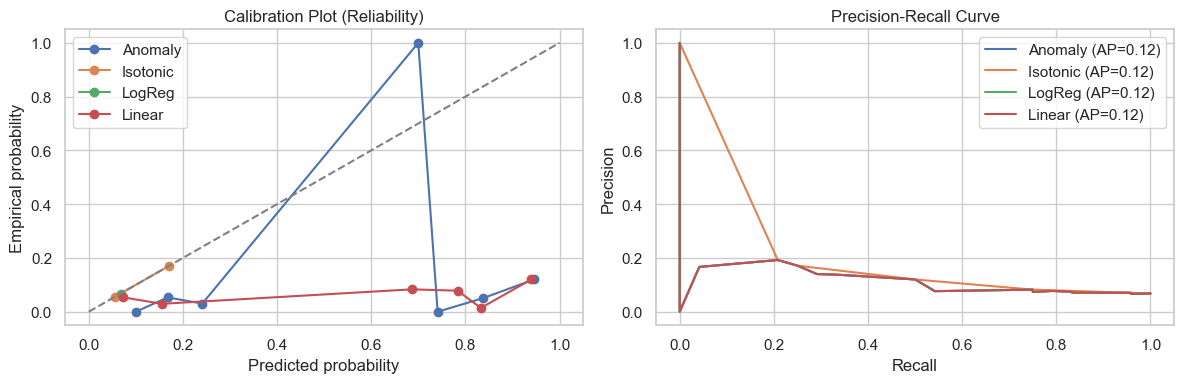

Saved with calibrated probabilities: Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_FewShot_calibrated.csv
Saved evaluation metrics: Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_FewShot_metrics.csv


/var/folders/0j/0cgjnq7x6_xgggqt92c7300r0000gn/T/ipykernel_16782/2924789302.py:92: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["prob_anomaly"] = np.clip(X.ravel(), 0, 1)
/var/folders/0j/0cgjnq7x6_xgggqt92c7300r0000gn/T/ipykernel_16782/2924789302.py:93: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["prob_iso"] = np.clip(prob_iso, 0, 1)
/var/folders/0j/0cgjnq7x6_xgggqt92c7300r0000gn/T/ipykernel_16782/2924789302.py:94: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Dat

In [24]:
calib = evaluate_anomaly_crash_prediction(df=llm_anomaly_fewshot,
    results_csv=f"{RESULTS_DIR}/{LLM_ANOMALY_FEWSHOT}.csv", 
    anomaly_score_col="anomaly_score",
    anomaly_label_col="anomaly_label",
    crash_actual_col="crash_actual_y",
    plot=True,
    n_bins=10,
    threshold=0.5)

Optimal threshold: 0.950 (F1=0.203)
Confusion matrix:
 [[302  29]
 [ 18   6]]
AUC-ROC: 0.611 | AP: 0.116
Dashboard saved to Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_FewShot_dashboard.png


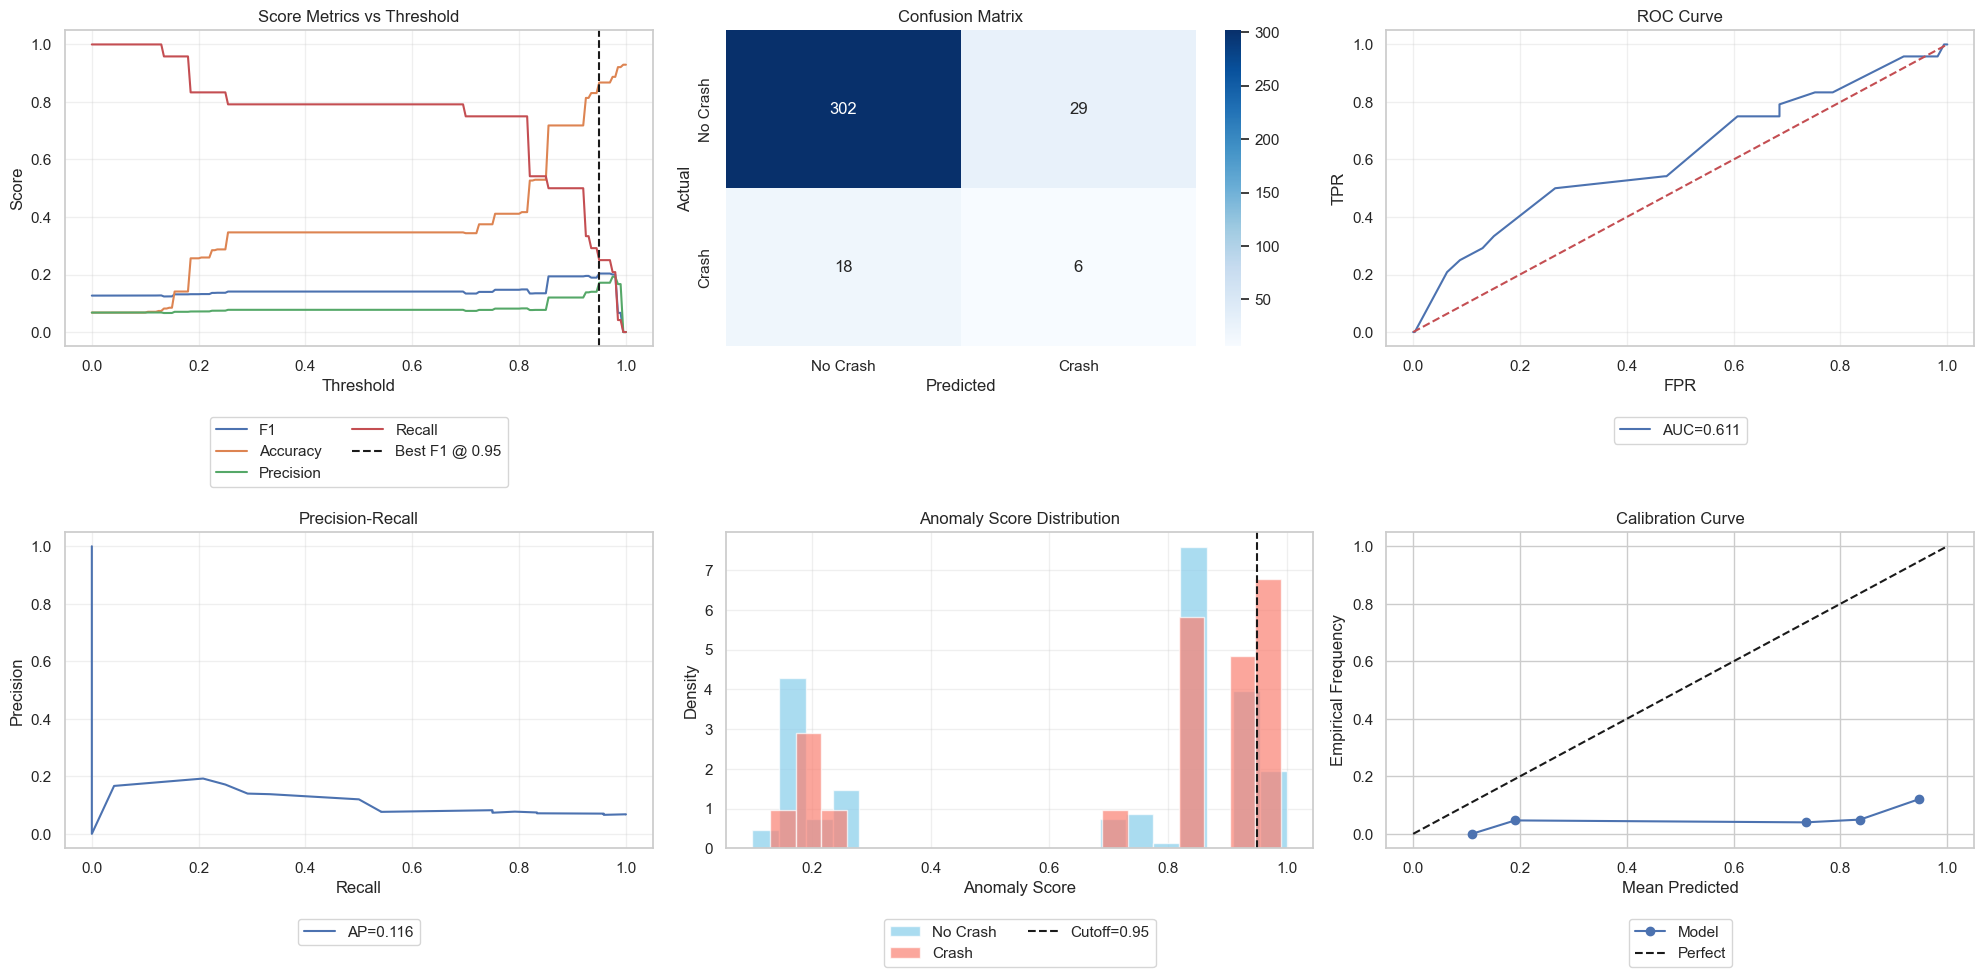


Classification Report (Best Threshold):

              precision    recall  f1-score   support

           0      0.944     0.912     0.928       331
           1      0.171     0.250     0.203        24

    accuracy                          0.868       355
   macro avg      0.558     0.581     0.566       355
weighted avg      0.892     0.868     0.879       355

Saved dashboard metrics: Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_FewShot_dashboard_metrics.csv


In [25]:
results_dashboard_few_shot = anomaly_crash_dashboard(
    df=llm_anomaly_fewshot,
    anomaly_score_col="anomaly_score",
    crash_actual_col="crash_actual_y",
    plot_thresholds=True,
    optimize_threshold=True,
    save_path=f"{RESULTS_DIR}/{LLM_ANOMALY_FEWSHOT}_dashboard.png"
)

Saved vibrant bar plot to Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_FewShot_bars_2023.png


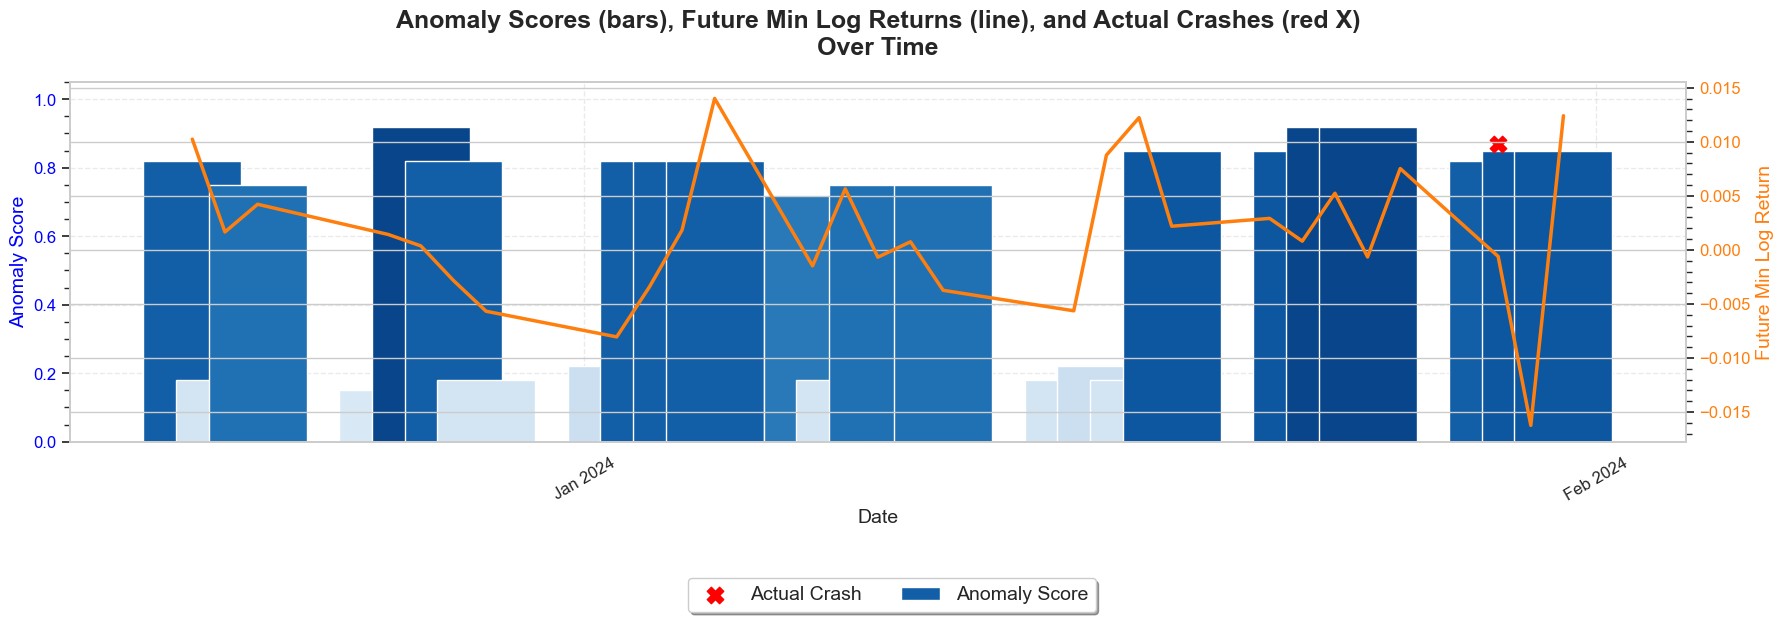

Saved vibrant bar plot to Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_FewShot_bars_2024.png


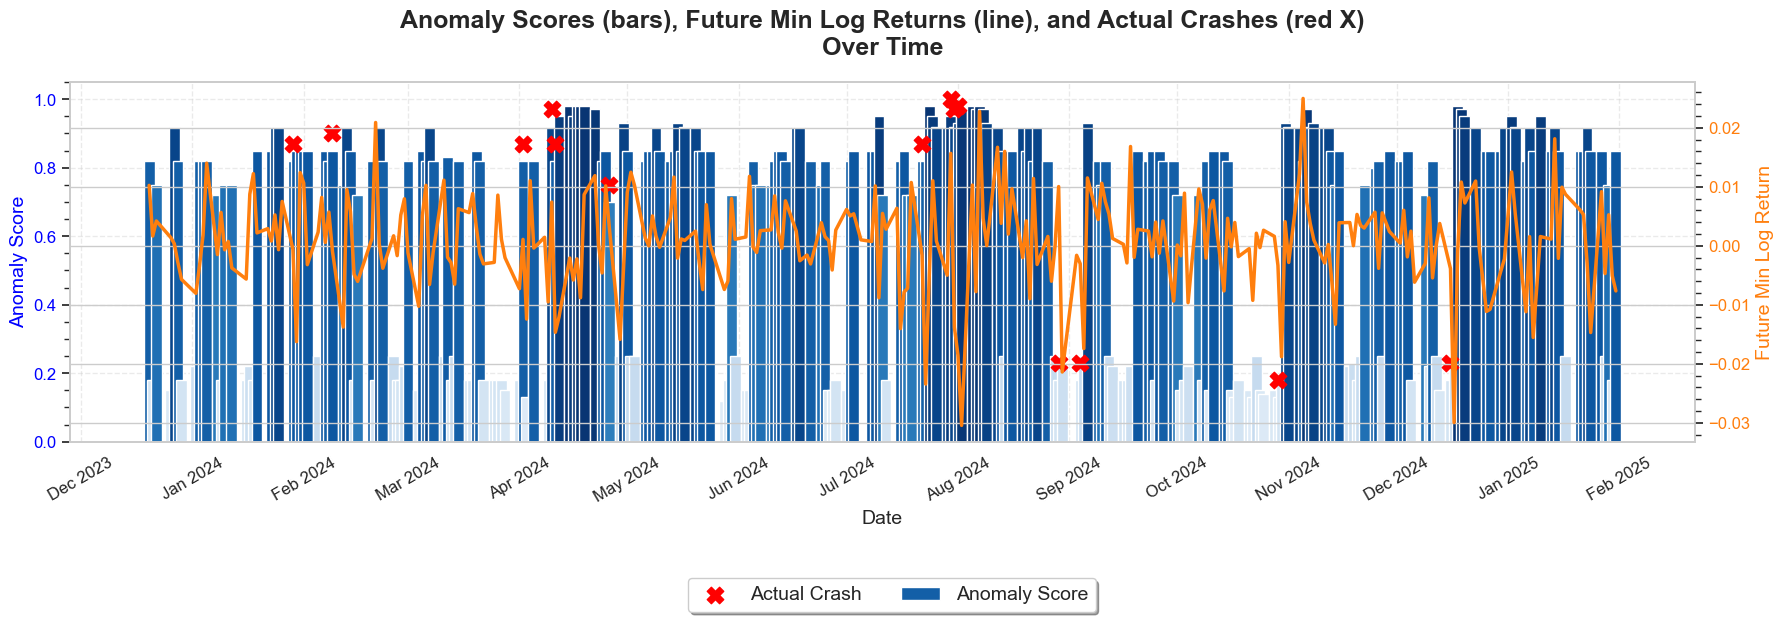

Saved vibrant bar plot to Results/Output/20250726 1012/Rolling_LLM_Anomaly_Scores_FewShot_bars_2025.png


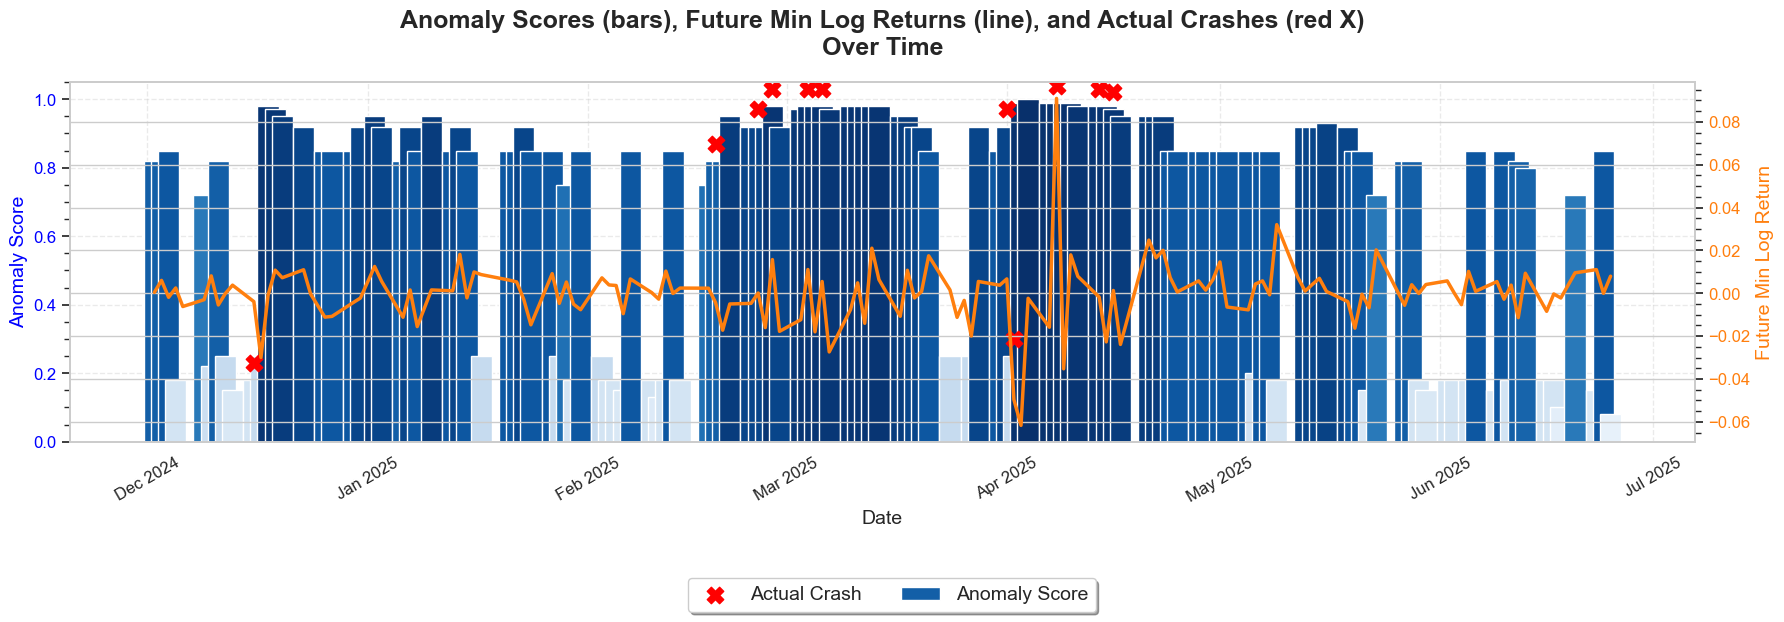

In [26]:
plot_anomaly_and_crashes_bars(
    df=llm_anomaly_fewshot,
    anomaly_score_col="anomaly_score",
    crash_actual_col="crash_actual_y",
    future_min_logret_col="future_min_logret",
    date_col="date",
    save_path=f"{RESULTS_DIR}/{LLM_ANOMALY_FEWSHOT}_bars.png"
)